In [2]:
# =====================================
# Import Required Libraries
# =====================================

# Data Handling
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    KFold,
    GridSearchCV
)

from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import RandomForestRegressor

# Model Save & Load
import joblib

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


In [4]:
# =====================================
# Load Dataset
# =====================================

df = pd.read_csv("vgsales.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [5]:
# =====================================
# Display First 5 Rows
# =====================================

df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [6]:
# =====================================
# Display Last 5 Rows
# =====================================

df.tail()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.0,0.0,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.0,0.0,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.0,0.0,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.0,0.0,0.01
16597,16600,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.0,0.0,0.01


In [7]:
# =====================================
# Dataset Shape
# =====================================

rows, columns = df.shape

print(f"Number of Rows    : {rows}")
print(f"Number of Columns : {columns}")

Number of Rows    : 16598
Number of Columns : 11


In [8]:
# =====================================
# Dataset Information
# =====================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [9]:
# =====================================
# Column Names
# =====================================

print("Dataset Columns:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Dataset Columns:

1. Rank
2. Name
3. Platform
4. Year
5. Genre
6. Publisher
7. NA_Sales
8. EU_Sales
9. JP_Sales
10. Other_Sales
11. Global_Sales


In [10]:
# =====================================
# Statistical Summary
# =====================================

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rank,16598.0,8300.605254,4791.853933,1.00,4151.25,8300.50,12449.75,16600.00
Year,16327.0,2006.406443,5.828981,1980.00,2003.00,2007.00,2010.00,2020.00
NA_Sales,16598.0,0.264667,0.816683,0.00,0.00,0.08,0.24,41.49
EU_Sales,16598.0,0.146652,0.505351,0.00,0.00,0.02,0.11,29.02
JP_Sales,16598.0,0.077782,0.309291,0.00,0.00,0.00,0.04,10.22
Other_Sales,16598.0,0.048063,0.188588,0.00,0.00,0.01,0.04,10.57
Global_Sales,16598.0,0.537441,1.555028,0.01,0.06,0.17,0.47,82.74


In [11]:
# =====================================
# Check Missing Values
# =====================================

missing_values = df.isnull().sum()

print("Missing Values in Each Column:\n")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Total Missing Values: 329


In [12]:
# =====================================
# Missing Value Percentage
# =====================================

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0]

print(missing_percentage)

Year         1.632727
Publisher    0.349440
dtype: float64


In [13]:
# =====================================
# Check Duplicate Records
# =====================================

duplicate_rows = df.duplicated().sum()

print("Duplicate Rows:", duplicate_rows)

Duplicate Rows: 0


In [14]:
# =====================================
# Remove Duplicate Records
# =====================================

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:")
print(df.shape)

Dataset Shape After Removing Duplicates:
(16598, 11)


In [15]:
# =====================================
# Data Types
# =====================================

df.dtypes

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

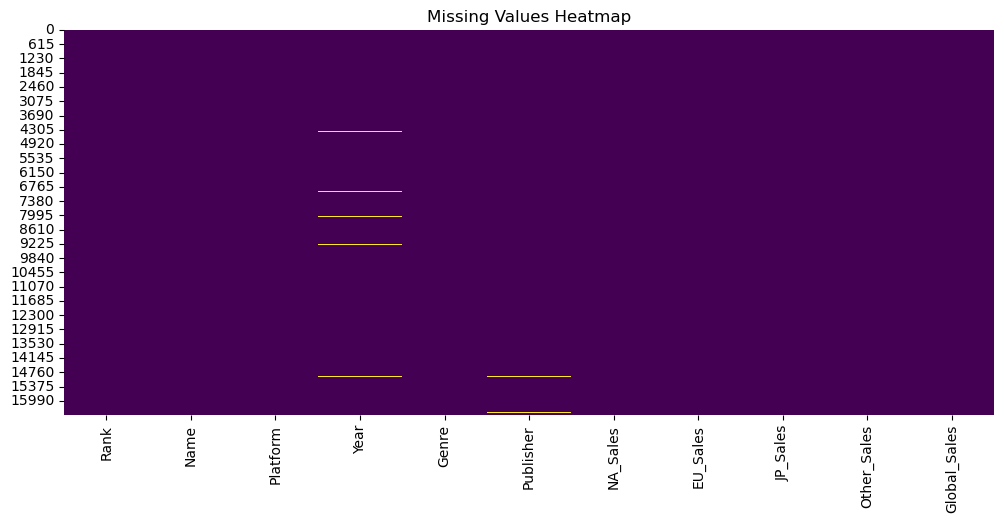

In [16]:
# =====================================
# Missing Value Heatmap
# =====================================

plt.figure(figsize=(12,5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")

plt.show()

In [17]:
# =====================================
# Unique Values
# =====================================

df.nunique()

Rank            16598
Name            11493
Platform           31
Year               39
Genre              12
Publisher         578
NA_Sales          409
EU_Sales          305
JP_Sales          244
Other_Sales       157
Global_Sales      623
dtype: int64

In [18]:
# =====================================
# Final Dataset Shape
# =====================================

print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

Rows : 16598
Columns : 11


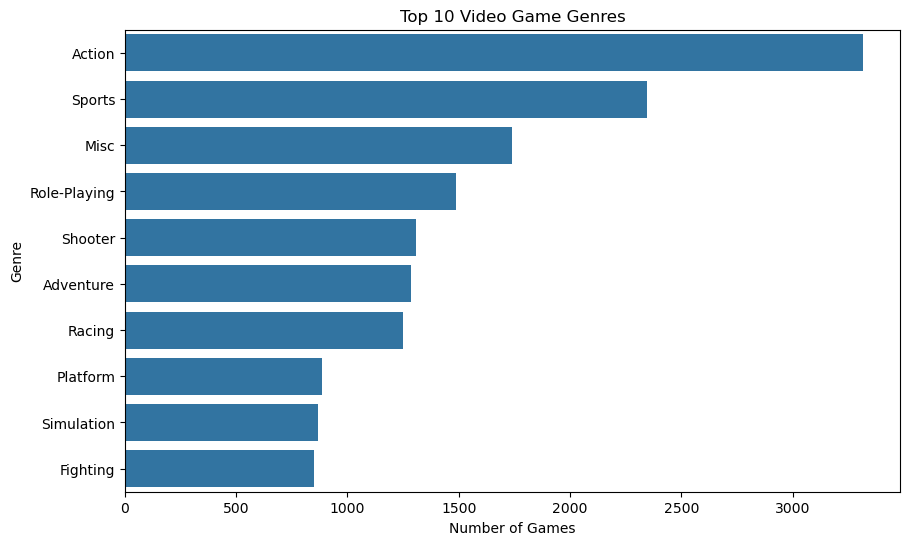

In [19]:
# =====================================
# Top 10 Game Genres
# =====================================

plt.figure(figsize=(10,6))

genre_count = df["Genre"].value_counts()

sns.barplot(
    x=genre_count.values[:10],
    y=genre_count.index[:10]
)

plt.title("Top 10 Video Game Genres")
plt.xlabel("Number of Games")
plt.ylabel("Genre")

plt.show()

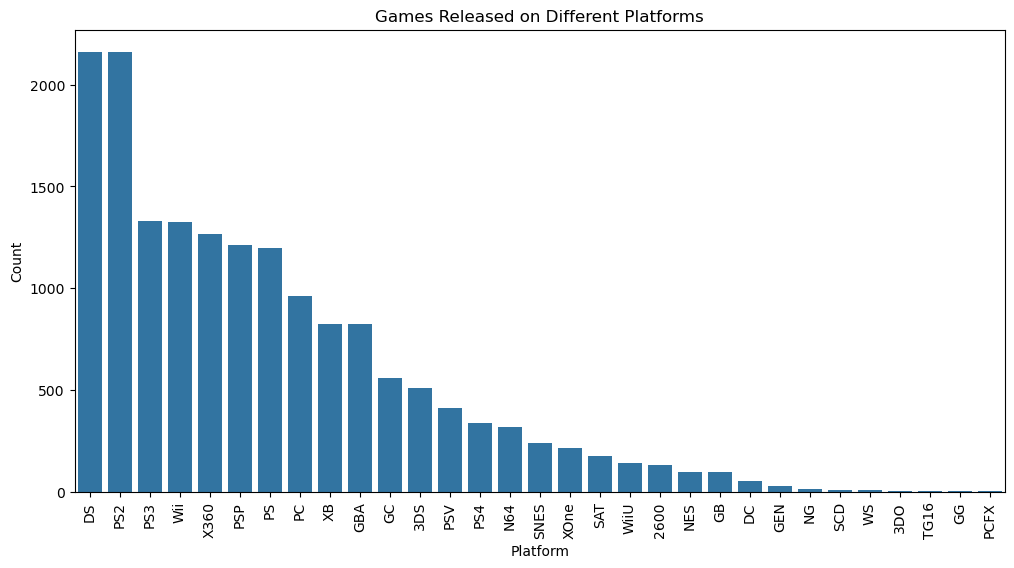

In [20]:
# =====================================
# Top Gaming Platforms
# =====================================

plt.figure(figsize=(12,6))

platform_count = df["Platform"].value_counts()

sns.barplot(
    x=platform_count.index,
    y=platform_count.values
)

plt.xticks(rotation=90)

plt.title("Games Released on Different Platforms")
plt.xlabel("Platform")
plt.ylabel("Count")

plt.show()

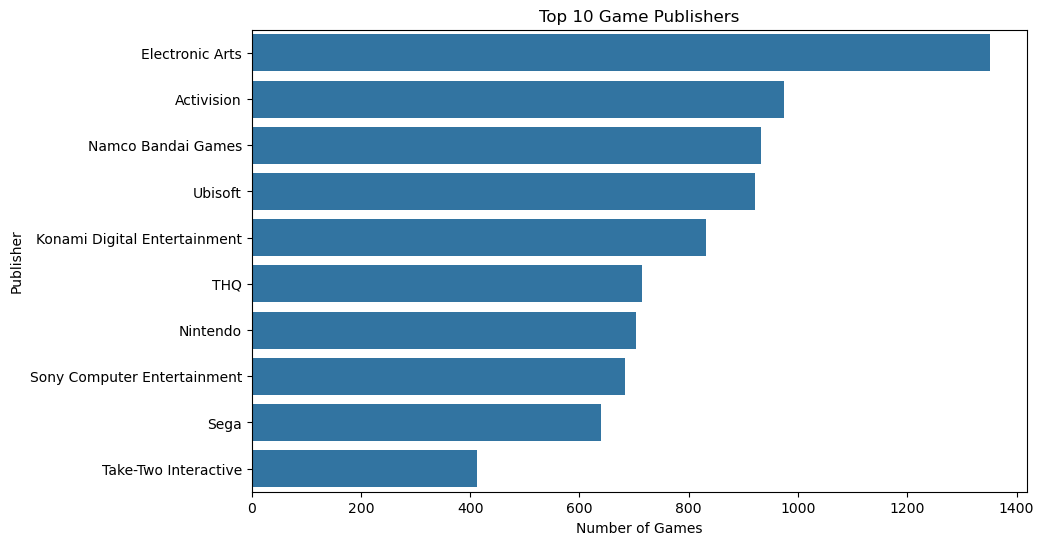

In [21]:
# =====================================
# Top 10 Publishers
# =====================================

top_publishers = df["Publisher"].value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_publishers.values,
    y=top_publishers.index
)

plt.title("Top 10 Game Publishers")
plt.xlabel("Number of Games")
plt.ylabel("Publisher")

plt.show()

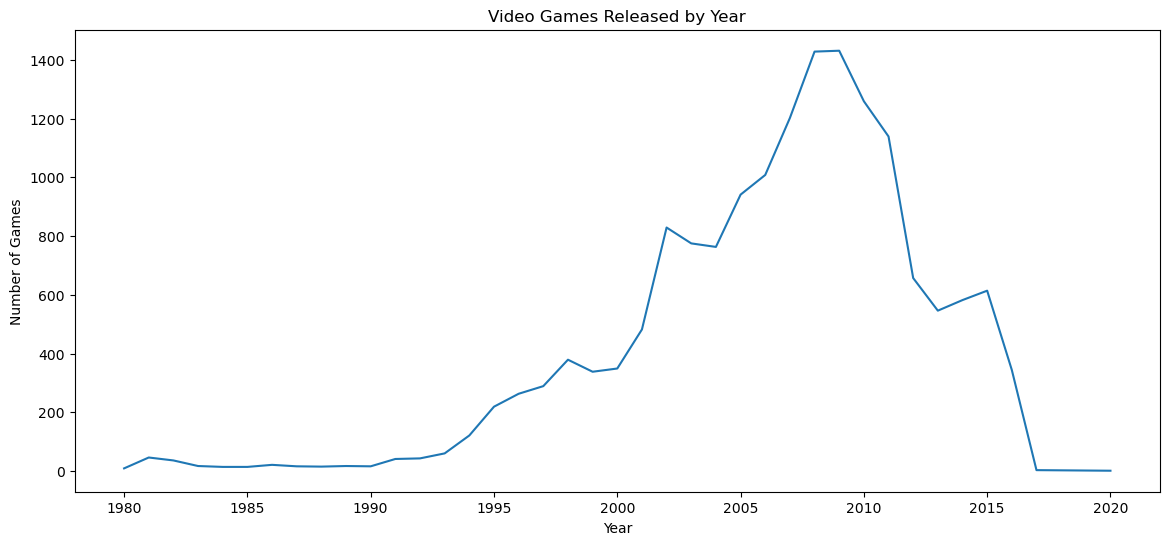

In [22]:
# =====================================
# Games Released by Year
# =====================================

plt.figure(figsize=(14,6))

df["Year"].value_counts().sort_index().plot()

plt.title("Video Games Released by Year")
plt.xlabel("Year")
plt.ylabel("Number of Games")

plt.show()

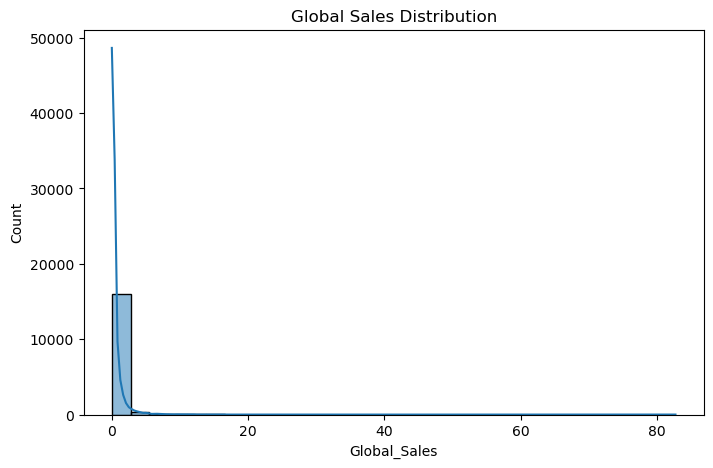

In [23]:
# =====================================
# Global Sales Distribution
# =====================================

plt.figure(figsize=(8,5))

sns.histplot(
    df["Global_Sales"],
    bins=30,
    kde=True
)

plt.title("Global Sales Distribution")

plt.show()

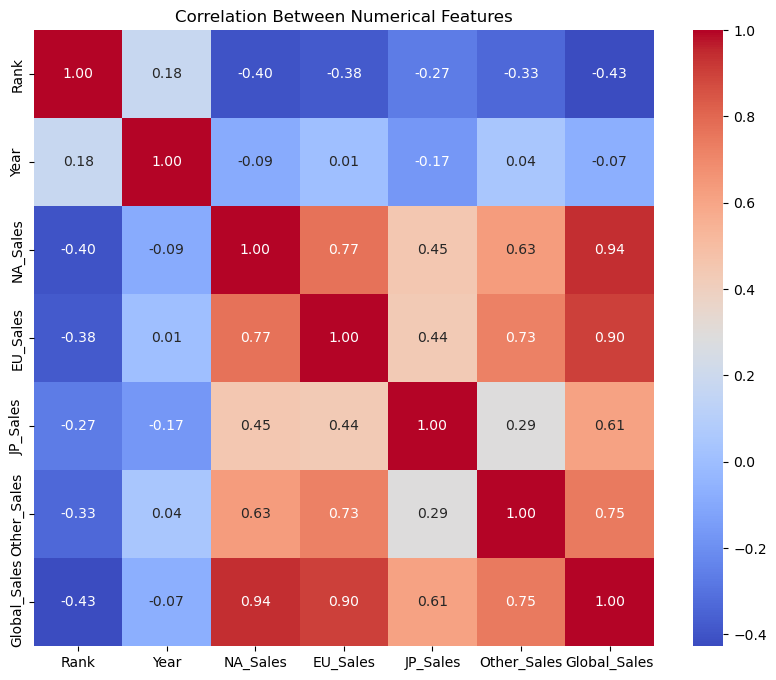

In [24]:
# =====================================
# Correlation Heatmap
# =====================================

numeric_df = df.select_dtypes(include=["number"])

plt.figure(figsize=(10,8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")

plt.show()

In [25]:
# =====================================
# Top 10 Best Selling Games
# =====================================

top_games = df.nlargest(10, "Global_Sales")

top_games[["Name", "Platform", "Global_Sales"]]

,Name,Platform,Global_Sales
0,Wii Sports,Wii,82.74
1,Super Mario Bros.,NES,40.24
2,Mario Kart Wii,Wii,35.82
3,Wii Sports Resort,Wii,33.00
4,Pokemon Red/Pokemon Blue,GB,31.37
5,Tetris,GB,30.26
6,New Super Mario Bros.,DS,30.01
7,Wii Play,Wii,29.02
8,New Super Mario Bros. Wii,Wii,28.62
9,Duck Hunt,NES,28.31


In [26]:
# =====================================
# Select Features and Target
# =====================================

features = [
    "Platform",
    "Year",
    "Genre",
    "Publisher",
    "NA_Sales",
    "EU_Sales",
    "JP_Sales",
    "Other_Sales"
]

target = "Global_Sales"

print("Selected Features:")
print(features)

print("\nTarget Variable:")
print(target)

Selected Features:
['Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']

Target Variable:
Global_Sales


In [27]:
# =====================================
# Create New DataFrame
# =====================================

data = df[features + [target]].copy()

data.head()

,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [28]:
# =====================================
# Fill Missing Values
# =====================================

data["Year"] = data["Year"].fillna(data["Year"].median())

print("Missing Values:\n")
print(data.isnull().sum())

Missing Values:

Platform         0
Year             0
Genre            0
Publisher       58
NA_Sales         0
EU_Sales         0
JP_Sales         0
Other_Sales      0
Global_Sales     0
dtype: int64


In [29]:
# =====================================
# Encode Categorical Columns
# =====================================

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

categorical_columns = [
    "Platform",
    "Genre",
    "Publisher"
]

for column in categorical_columns:
    data[column] = encoder.fit_transform(data[column])

print("Categorical columns encoded successfully.")

Categorical columns encoded successfully.


In [30]:
# =====================================
# Features and Target
# =====================================

X = data.drop(columns=[target])

y = data[target]

print("Feature Shape :", X.shape)
print("Target Shape  :", y.shape)

Feature Shape : (16598, 8)
Target Shape  : (16598,)


In [31]:
# =====================================
# Split Dataset
# =====================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Samples :", X_train.shape[0])
print("Testing Samples  :", X_test.shape[0])

Training Samples : 13278
Testing Samples  : 3320


In [32]:
# =====================================
# Standardize Features
# =====================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature Scaling Completed.")

Feature Scaling Completed.


In [33]:
# =====================================
# Train Random Forest Regressor
# =====================================

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [34]:
# =====================================
# Predict on Test Data
# =====================================

y_pred = model.predict(X_test)

print("Prediction completed successfully.")

Prediction completed successfully.


In [35]:
# =====================================
# Model Evaluation
# =====================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error :", round(mae,3))
print("Mean Squared Error  :", round(mse,3))
print("Root Mean Squared Error :", round(rmse,3))
print("R2 Score :", round(r2,3))

Mean Absolute Error : 0.044
Mean Squared Error  : 0.831
Root Mean Squared Error : 0.912
R2 Score : 0.802


In [36]:
# =====================================
# Actual vs Predicted
# =====================================

comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
0,0.15,0.152194
1,0.40,0.398590
2,0.02,0.022267
3,0.03,0.019457
4,0.36,0.365960
5,2.24,2.163117
6,0.39,0.401220
7,0.65,0.646499
8,0.21,0.213368
9,0.44,0.440018


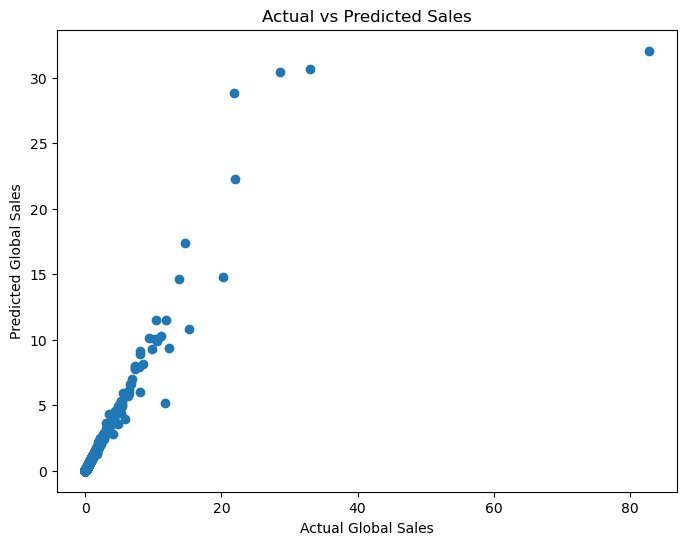

In [37]:
# =====================================
# Actual vs Predicted Plot
# =====================================

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Global Sales")
plt.ylabel("Predicted Global Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

In [38]:
# =====================================
# Save Trained Model
# =====================================

import joblib

joblib.dump(model, "video_game_sales_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [39]:
# =====================================
# Feature Importance
# =====================================

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
4,NA_Sales,0.852640
5,EU_Sales,0.103803
6,JP_Sales,0.030316
7,Other_Sales,0.010501
0,Platform,0.000873
1,Year,0.000757
2,Genre,0.000691
3,Publisher,0.000419


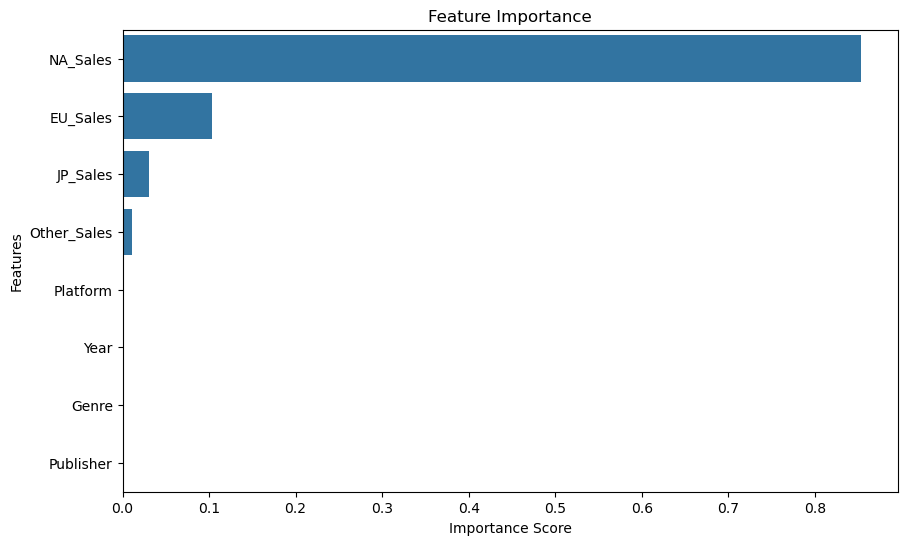

In [40]:
# =====================================
# Feature Importance Graph
# =====================================

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [41]:
# =====================================
# Save Feature Importance
# =====================================

feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("Feature Importance saved successfully.")

Feature Importance saved successfully.


In [42]:
# =====================================
# Final Output
# =====================================

print("="*60)
print("Video Game Sales Prediction Project Completed")
print("="*60)

print(f"R² Score : {r2:.3f}")
print(f"MAE      : {mae:.3f}")
print(f"RMSE     : {rmse:.3f}")

print("\nTop 5 Important Features:")
print(feature_importance.head())

print("\nProject Successfully Completed.")

Video Game Sales Prediction Project Completed
R² Score : 0.802
MAE      : 0.044
RMSE     : 0.912

Top 5 Important Features:
       Feature  Importance
4     NA_Sales    0.852640
5     EU_Sales    0.103803
6     JP_Sales    0.030316
7  Other_Sales    0.010501
0     Platform    0.000873

Project Successfully Completed.
